# 1차시 : 1315 정서진
데이터명: 1315정서진_수질지수예측.csv (예, weather2023.xlsx)

### [파일 제출 방법] ###
1. Jupyter Notebook 파일 저장
2. 모든 셀 실행하기
 - 오류 없이 실행되었는지 확인
 - 그래프와 성능평가 결과가 모두 출력되었는지 확인
3. ... → 내보내기(Export) → HTML
4. 아래 2개 파일을 모두 제출 
  - (2-3차시)학번이름(주제).ipynb
  - (2-3차시)학번이름(주제).html


STEP 0. 1차시에 작성한 내용을 옮겨 적으세요. (3점)

1. 탐구 질문: 물의 수온, pH, 용존산소등 수질 측정값으로 수질지수(WQI)를 예측할 수 있을까?
2. 목표변수(y): WQI
3. 특성변수(X)후보: 수온, 용존산소량, pH, BOD, 질산염
4. 문제 유형: 회귀

※ 특성변수(X)는 아직 최종 확정이 아닙니다. 
데이터 전처리와 시각화 결과를 확인한 후 변경할 수 있습니다.

STEP 1. 데이터 불러오기 및 데이터 상태확인· 전처리 하기(5점)

1. 데이터 불러오기
2. 데이터 크기 확인
3. 열이름과 자료형 확인
4. 결측치 확인
5. 중복값 확인
6. 필요하면 전처리 수행


In [39]:
import pandas as pd
import matplotlib.pyplot as plt
# 1~4번, 8~9번은 필수, 6~7번은 필요한 경우 처리
# 1. 데이터 파일 불러오기
water = pd.read_csv('1315정서진_수질지수예측.csv')

# 2. 데이터의 행과 열의 수 확인하기
print(water.shape)

# 3. 열 이름과 데이터 자료형 확인하기
water.info()

# 4. 각 열의 결측치 개수 확인하기
print(water.isnull().sum())

# 5. 중복된 행의 개수 확인하기
print(water.duplicated().sum())

# 6~7의 결측치 및 중복값이 없는 경우에는 처리하지 않아도 됩니다.
# 6. 필요한 경우 결측치 처리하기


# 7. 필요한 경우 중복 데이터 처리하기


# 8. 분석에 필요하지 않은 열이 있다면 처리하기
water.drop(['Temperature'], axis = 1, inplace = True)

# 9. 전처리 후 데이터 상태 다시 확인하기
water.head()

(295, 10)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 295 entries, 0 to 294
Data columns (total 10 columns):
 #   Column                             Non-Null Count  Dtype  
---  ------                             --------------  -----  
 0   Temperature                        295 non-null    float64
 1   Dissolved Oxygen                   295 non-null    float64
 2   pH                                 295 non-null    float64
 3   Bio-Chemical Oxygen Demand (mg/L)  295 non-null    float64
 4   Faecal Streptococci (MPN/ 100 mL)  295 non-null    float64
 5   Nitrate (mg/ L)                    295 non-null    float64
 6   Faecal Coliform (MPN/ 100 mL)      295 non-null    float64
 7   Total Coliform (MPN/ 100 mL)       295 non-null    float64
 8   Conductivity (mho/ Cm)             295 non-null    float64
 9   WQI                                295 non-null    float64
dtypes: float64(10)
memory usage: 23.2 KB
Temperature                          0
Dissolved Oxygen                    

,Dissolved Oxygen,pH,Bio-Chemical Oxygen Demand (mg/L),Faecal Streptococci (MPN/ 100 mL),Nitrate (mg/ L),Faecal Coliform (MPN/ 100 mL),Total Coliform (MPN/ 100 mL),Conductivity (mho/ Cm),WQI
0,9.95,7.85,0.15,90.0,0.255,22.5,180.0,134.5,27.143963
1,9.65,7.70,0.45,205.0,0.200,62.5,410.0,77.0,15.780001
2,9.90,7.65,0.55,100.0,0.100,26.0,200.0,101.5,20.612438
3,9.65,7.55,0.35,300.0,0.250,97.5,600.0,148.0,29.820475
4,9.55,7.80,0.25,190.0,0.150,47.5,380.0,106.0,21.498569


STEP 2. 특성변수 후보와 목표변수의 관계 시각화하기(4점)

- 1차시에서 선택한 특성변수(X) 후보 중 2개 이상을 선택하여 각각 목표변수(y)와의 관계를 시각화 하세요. 
-예. temp <-> sunshine, humi <-> sunshine

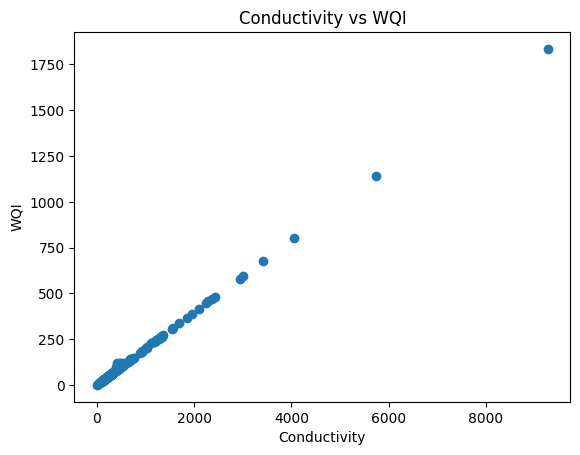

In [40]:
# 시각화1: 특성변수 후보 1과 목표변수의 관계를 확인할 수 있는 그래프 그리기
plt.scatter(water['Conductivity (mho/ Cm)'], water['WQI'])

# 그래프 제목 설정하기
plt.title('Conductivity vs WQI')

# x축과 y축 이름 설정하기
plt.xlabel('Conductivity')
plt.ylabel('WQI')

# 그래프 출력하기
plt.show()

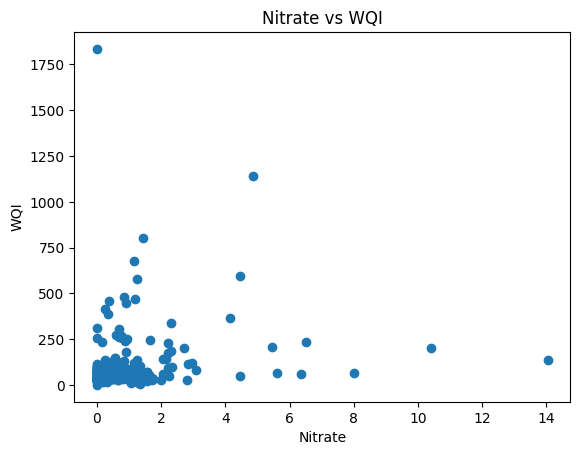

In [41]:
# 시각화2: 특성변수 후보 2와 목표변수의 관계를 확인할 수 있는 그래프 그리기
plt.scatter(water['Nitrate (mg/ L)'], water['WQI'])

# 그래프 제목 설정하기
plt.title('Nitrate vs WQI')

# x축과 y축 이름 설정하기
plt.xlabel('Nitrate')
plt.ylabel('WQI')

# 그래프 출력하기
plt.show()


STEP 3. 최종 특성변수 X와 목표변수 y 정하기 (2점)

In [42]:

# 최종적으로 사용할 특성변수(X) 선택하기
X = water[['Conductivity (mho/ Cm)', 'Bio-Chemical Oxygen Demand (mg/L)']]

# 예측할 목표변수(y) 선택하기
y = water['WQI']

STEP 4. 훈련 데이터와 테스트 데이터로 나누기 (3점)

In [43]:
from sklearn.model_selection import train_test_split

# 전체 데이터를 훈련용 데이터와 테스트용 데이터로 나누기
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size = 0.2, random_state = 42
)

# 훈련 데이터와 테스트 데이터의 크기 확인하기
print("훈련데이터: ", X_train.shape)
print("테스트데이터: ", X_test.shape)

훈련데이터:  (236, 2)
테스트데이터:  (59, 2)


STEP 5. 모델1 선택 및 학습 (4점)
- 모델1 이름: 선형회귀

In [49]:
# 1. 사용할 머신러닝 모델의 라이브러리 불러오기
from sklearn.linear_model import LinearRegression

# 2. 모델1 생성하기
model = LinearRegression()

# 3. 훈련 데이터를 이용하여 모델1 학습시키기
model.fit(X_train, y_train)

# 4. 테스트 데이터로 예측하기
pred = model.predict(X_test)

STEP 6. 모델 1 성능 평가(3점)

<성능지표> 
회귀: MAE, MSE, RMSE, R² 등

In [45]:
# 모델1의 성능을 평가하기 위한 함수 불러오기
from sklearn.metrics import mean_absolute_error, r2_score

# 성능지표 1 계산하여 출력하기(반드시 성능지표 이름과 결과가 함께 출력되어야 함)
mae = mean_absolute_error(y_test, pred)

print("선형회귀 MAE: ", mae)


# 성능지표 2 계산하여 출력하기(반드시 성능지표 이름과 결과가 함께 출력되어야 함)
r2 = r2_score(y_test, pred)

print("선형회귀 R2: ", r2)

선형회귀 MAE:  1.273815584447982
선형회귀 R2:  0.9996991757807375


STEP 7. 실제값과 예측값 비교하기(시각화) (2점)

회귀: 실제값과 예측값의 관계를 산점도로 나타내시오.

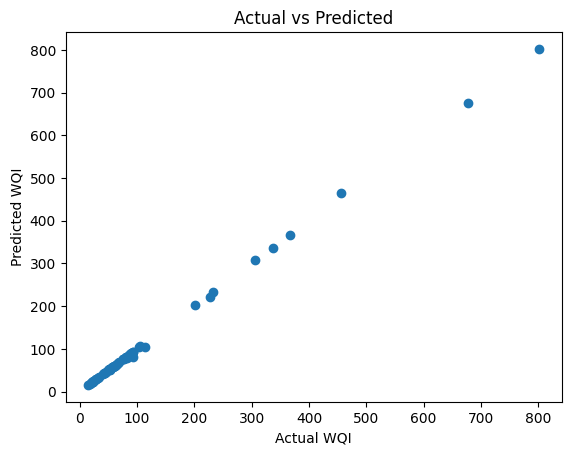

In [46]:
plt.scatter(y_test, pred)
plt.xlabel('Actual WQI')
plt.ylabel('Predicted WQI')
plt.title('Actual vs Predicted')
plt.show()

STEP 8. 모델2 학습, 예측, 성능평가 (6점)
※ 모델1과 동일한 테스트 데이터 및 성능지표 2개를 사용하세요.

In [47]:
# 1. 모델2에 필요한 라이브러리 불러오기
from sklearn.ensemble import RandomForestRegressor

# 2. 모델2 생성하기
rf_model = RandomForestRegressor(n_estimators=100, random_state=42)

# 3. 동일한 훈련 데이터를 이용하여 모델2 학습시키기
rf_model.fit(X_train, y_train)

# 4. 동일한 테스트 데이터로 예측하기
rf_pred = rf_model.predict(X_test)

# 5. 성능지표 1 계산하여 출력하기(반드시 성능지표 이름과 결과가 함께 출력되어야 함)
rf_mae = mean_absolute_error(y_test, rf_pred)

print("랜덤포레스트 MAE: ", rf_mae)

# 6. 성능지표 2 계산하여 출력하기(반드시 성능지표 이름과 결과가 함께 출력되어야 함)
rf_r2 = r2_score(y_test, rf_pred)

print("랜덤포레스트 R2: ", rf_r2)

랜덤포레스트 MAE:  8.703227852774553
랜덤포레스트 R2:  0.9523260941016309


STEP 9. 새로운 데이터로 예측하기(3점)

학습에 사용한 특성변수의 값을 직접 정하여 새로운 데이터를 1개 이상 만들고 예측하세요.

In [48]:
# 학습에 사용한 특성변수와 같은 형태로 새로운 데이터 만들기
# ※ 새로운 데이터는 STEP 3에서 선택한 특성변수(X)와 동일한 열 이름 및 개수로 구성하세요.
new_data = pd.DataFrame({
    'Conductivity (mho/ Cm)': [100.0],
    'Bio-Chemical Oxygen Demand (mg/L)': [1.0]
})

# 모델1 또는 모델2 중 하나를 선택하여 새로운 데이터 예측하기
new_pred = rf_model.predict(new_data)

# 예측 결과 출력하기
print('예측 수질지수: ', new_pred[0])

예측 수질지수:  20.08035471739996
